# 300. Can kmerseek find the source protein of a short mass-spec peptide, with a known false-discovery rate?

**Question.** A gut metaproteomics run gives peptides of 9 to 30 residues that match nothing
in the study's own database. Can kmerseek find which protein each one came from, and say how
often it is wrong?

**What this decides.** Whether peptide lookup is a use of kmerseek worth a paper section
(this notebook, kill test 2) and whether kill test 3 is worth starting. Step 0 decides if
either is possible at all, before any search runs.

**Words.** A *peptide* here is 9 to 30 residues. A *kmerseek setting* is one combination of
alphabet, k-size, scaled, mismatch penalty and low-complexity mask. A *decoy* is a fake peptide
used to count false hits. *FDR*, the false-discovery rate, is decoy hits divided by target hits
at a given E-value cut.

**Step 0 gate, fixed before any number was computed.** If no setting of an alphabet reaches
E < 0.01 for one exact 14-residue window against UHGP-90, and no pair of exact windows within
a 30-residue peptide reaches it either, peptide lookup is dead for that alphabet. If every
alphabet is dead, the notebook stops at Step 0.

**Pass rule for steps 1-6, fixed now.** At an FDR of 1% with the region E-value as the cut:
PASS if (1) at least 90% of 1,000 spiked peptides with one or two conservative swaps are
recovered and kmerseek finds at least 25% more real unmatched peptides than
`diamond --ultra-sensitive`; (2) the E-value at which the decoy FDR crosses 1% is within a
factor of 2 of E = 0.01; (3) all 10,000 peptides run in under 60 s on 8 cores.
DROP if Step 0 kills the alphabet, or if spiked recovery is below 50% at 1% FDR.
Anything else is FAIL.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

sys.path.insert(0, str(Path.cwd()))
sys.path.insert(0, str(Path.cwd().parent / "nextflow-runs" / "peptide-lookup" / "bin"))
import pubfig as pf
from alphabets import CLUSTERS

pf.use_style()
pl.Config.set_tbl_rows(60).set_tbl_cols(20).set_fmt_str_lengths(80).set_tbl_width_chars(
    200
)

DATA = Path(os.environ.get("NB300_DATA", "300_data")) / "step0"
FIGURES = Path("figures/300")
GATE_E = 0.01
DATABASES = {"swissprot": "Swiss-Prot", "uniref90": "UniRef90", "uhgp90": "UHGP-90"}

# Alphabet groups by class count (clear-figures rule 7d), drawn in this order.
GROUPS = [
    ("2-3 classes", 2, 3),
    ("4-8 classes", 4, 8),
    ("12-18 classes", 12, 18),
    ("20 classes", 20, 20),
]
GROUP_TINT = {
    "2-3 classes": "#9ecae1",
    "4-8 classes": "#a1d99b",
    "12-18 classes": "#bcbddc",
    "20 classes": "#636363",
}
HIGHLIGHT = "massspec18"
HIGHLIGHT_COLOUR = pf.OKABE_ITO["vermillion"]


def group_of(alphabet):
    n = len(CLUSTERS[alphabet])
    return next(name for name, lo, hi in GROUPS if lo <= n <= hi)


ALPHABET_ORDER = sorted(CLUSTERS, key=lambda a: (len(CLUSTERS[a]), a))

## 1. The databases, as read on the day

Each file was downloaded by `nextflow-runs/peptide-lookup/sbatch/download.sbatch` and counted
by `bin/db_composition.py`. `n_residues` counts every letter; class frequencies use only the
20 canonical residues (`n_canonical`). UHGP-90 is MGnify human-gut catalogue v2.0.2
(`uhgp-90.tar.gz`); v3.0 exists, but it names its file `protein_catalogue-90`, not UHGP.

shape: (6, 4)
┌────────────────────────────────────────────┬─────────────┬───────────────────────────────┬──────────────────────┐
│ file                                       ┆ bytes       ┆ last_modified                 ┆ date_downloaded      │
│ ---                                        ┆ ---         ┆ ---                           ┆ ---                  │
│ str                                        ┆ i64         ┆ str                           ┆ str                  │
╞════════════════════════════════════════════╪═════════════╪═══════════════════════════════╪══════════════════════╡
│ human_UP000005640_9606_additional.fasta.gz ┆ 41421368    ┆ Tue, 15 Sep 2026 09:21:31 GMT ┆ 2026-10-20T20:56:07Z │
│ uhgp-90.tar.gz                             ┆ 10573087336 ┆ Tue, 07 Dec 2021 05:42:57 GMT ┆ 2026-10-21T01:19:32Z │
│ crap.fasta                                 ┆ 42092       ┆ Mon, 04 Mar 2019 19:58:01 GMT ┆ 2026-10-21T01:19:43Z │
│ human_UP000005640_9606.fasta.gz            ┆ 7728297    

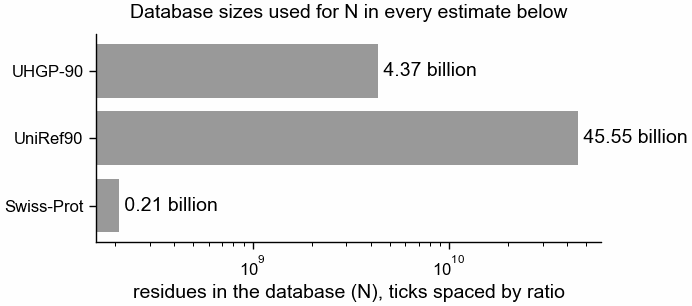

In [2]:
import json

manifest = pl.read_csv(DATA / "db_manifest.tsv", separator="\t")
print(manifest.select("file", "bytes", "last_modified", "date_downloaded"))
comp = pl.DataFrame(
    [
        {
            k: v
            for k, v in json.loads(
                (DATA / f"composition_{db}.json").read_text()
            ).items()
            if k != "letters"
        }
        for db in DATABASES
    ]
)
print(
    comp.select("database", "n_sequences", "n_residues", "n_canonical", "date_counted")
)

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 40)
y = np.arange(len(comp))
ax.barh(y, comp["n_residues"], color=pf.GREY)
for yi, n in zip(y, comp["n_residues"]):
    ax.text(n, yi, f" {n / 1e9:.2f} billion", va="center")
ax.set_yticks(y, [DATABASES[d] for d in comp["database"]])
ax.set_xscale("log")
ax.set_xlabel("residues in the database (N), ticks spaced by ratio")
ax.set_title("Database sizes used for N in every estimate below")
pf.save(fig, FIGURES / "database_sizes_swissprot_uniref90_uhgp90")

## 2. Two estimates of the smallest E-value one exact window can reach

Neither is a kmerseek measurement, so neither uses a kmerseek column name.

* `expected_hits_counting`: the number of places in the database where the window's class
  string turns up by chance. It is N_start x Pr(word). Pr(word) is the product of the class
  frequencies of the window's residues, measured on the database itself, and
  N_start = n_residues - n_sequences x (L - 1) is the number of places a word of L residues can
  start.
* `region_evalue_ka_fit`: kmerseek's region E-value formula, K m n e^(-r lambda S), for a
  perfect match: S = L (one point per matching position), m = L, n = the database's k-mer
  count divided by scaled. lambda is the Karlin-Altschul lambda for the chance u that a window
  position and a database position share a class. K and r (kmerseek calls r `r_database`) are
  the medians of the fits kmerseek stored in the dark-set 0.4 indexes for that setting. Those
  indexes were built on other proteomes (the dark-set reference set minus one clade), so using
  their K and r for these three databases is an assumption.

Both are medians over the same 1,000 windows of 60 residues drawn at random from Swiss-Prot
(seed 300), read as their first L residues. A window shorter than k holds no seed, so a setting
has no value below its k. A pair is two exact windows in one 30-residue peptide with one
unmatched residue between them, the first 14 residues long (formula in `bin/evalue_floor.py`).

Lower is better: E < 0.01 means a chance match of that window is rare enough to call.

In [3]:
est = pl.read_csv(
    DATA / "floor_estimates.tsv.gz", separator="\t", infer_schema_length=None
)
settings = pl.read_csv(DATA / "settings.tsv", separator="\t", infer_schema_length=None)
gate = pl.read_csv(DATA / "gate_uhgp90.tsv", separator="\t", infer_schema_length=None)
min_len = pl.read_csv(
    DATA / "floor_min_length.tsv", separator="\t", infer_schema_length=None
)

## 3. The gate: which alphabets are alive against UHGP-90

For each alphabet, the best (smallest) estimate over its settings for one exact 14-residue
window, and the best pair inside 30 residues. Alive when any of the three is below 0.01.

shape: (20, 7)
┌──────────────────────────┬───────────────────────────────────┬─────────────────────────────────┬──────────────────────────────────┬────────────────┬─────────┬───────────────────────────────────────┐
│ alphabet                 ┆ best_expected_hits_counting_at_14 ┆ best_region_evalue_ka_fit_at_14 ┆ best_expected_hits_counting_pair ┆ smallest_ksize ┆ verdict ┆ reason                                │
│ ---                      ┆ ---                               ┆ ---                             ┆ ---                              ┆ ---            ┆ ---     ┆ ---                                   │
│ str                      ┆ f64                               ┆ f64                             ┆ f64                              ┆ i64            ┆ str     ┆ str                                   │
╞══════════════════════════╪═══════════════════════════════════╪═════════════════════════════════╪══════════════════════════════════╪════════════════╪═════════╪═════════════════════

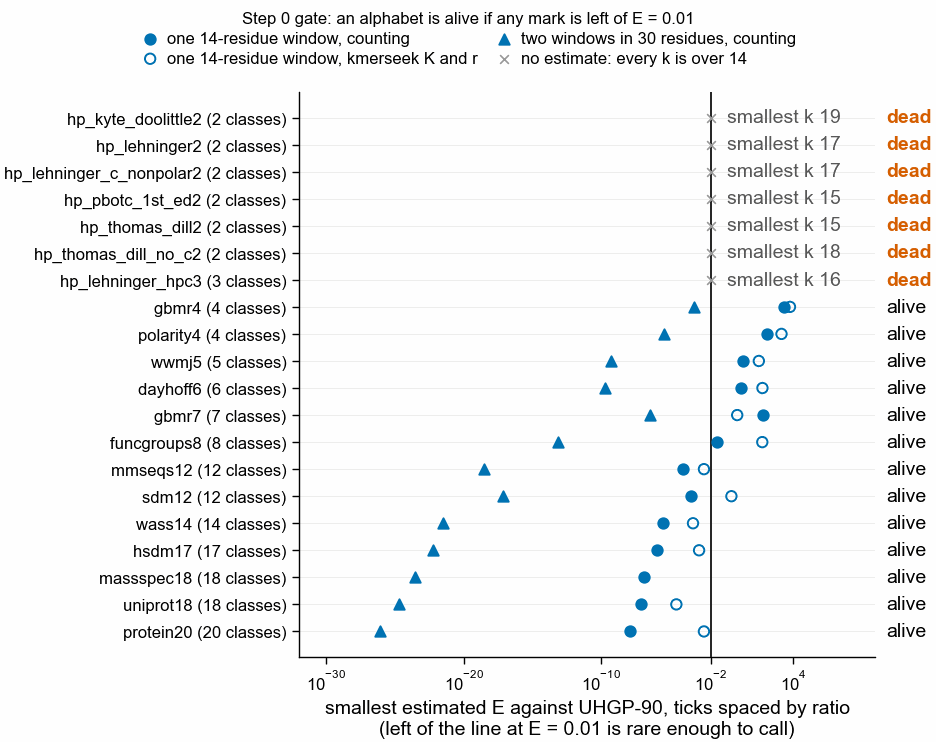

In [4]:
gate = gate.with_columns(
    pl.col("alphabet")
    .replace_strict({a: i for i, a in enumerate(ALPHABET_ORDER)}, return_dtype=pl.Int64)
    .alias("_o")
).sort("_o")
print(gate.drop("_o", "database"))

MARKS = [
    ("best_expected_hits_counting_at_14", "one 14-residue window, counting", "o", True),
    (
        "best_region_evalue_ka_fit_at_14",
        "one 14-residue window, kmerseek K and r",
        "o",
        False,
    ),
    (
        "best_expected_hits_counting_pair",
        "two windows in 30 residues, counting",
        "^",
        True,
    ),
]
fig, ax = pf.figure(120, 95)
rows = gate["alphabet"].to_list()
y = {a: i for i, a in enumerate(rows)}
ax.axvline(GATE_E, color="black", lw=0.6)
for col, label, marker, filled in MARKS:
    vals = gate[col].to_list()
    xs = [v for v in vals if v is not None]
    ys = [y[a] for a, v in zip(rows, vals) if v is not None]
    ax.scatter(
        xs,
        ys,
        marker=marker,
        s=14,
        label=label,
        facecolors=pf.OKABE_ITO["blue"] if filled else "none",
        edgecolors=pf.OKABE_ITO["blue"],
        linewidths=0.7,
        zorder=3,
    )
ax.scatter(
    [],
    [],
    marker="x",
    s=10,
    color=pf.GREY,
    lw=0.6,
    label="no estimate: every k is over 14",
)
for a, verdict, k_min in gate.select(
    "alphabet", "verdict", "smallest_ksize"
).iter_rows():
    if all(gate.filter(pl.col("alphabet") == a)[c][0] is None for c, *_ in MARKS):
        ax.scatter([GATE_E], [y[a]], marker="x", s=10, color=pf.GREY, lw=0.6, zorder=3)
        ax.annotate(
            f"smallest k {k_min}",
            (GATE_E, y[a]),
            xytext=(6, 0),
            textcoords="offset points",
            ha="left",
            va="center",
            color="#555555",
        )
    ax.text(
        1.02,
        y[a],
        verdict,
        transform=ax.get_yaxis_transform(),
        va="center",
        color=HIGHLIGHT_COLOUR if verdict == "dead" else "black",
        fontweight="bold" if verdict == "dead" else "normal",
    )
ax.set_yticks(range(len(rows)), [f"{a} ({len(CLUSTERS[a])} classes)" for a in rows])
for yy in range(len(rows)):
    ax.axhline(yy, color="#eeeeee", lw=0.4, zorder=0)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlim(1e-32, 1e10)
ax.xaxis.set_major_locator(mpl.ticker.FixedLocator([1e-30, 1e-20, 1e-10, 1e-2, 1e4]))
ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
ax.set_xlabel(
    "smallest estimated E against UHGP-90, ticks spaced by ratio\n"
    "(left of the line at E = 0.01 is rare enough to call)"
)
pf.shared_legend(
    fig,
    ncol=2,
    frameon=False,
    title="Step 0 gate: an alphabet is alive if any mark is left of E = 0.01",
)
pf.save(fig, FIGURES / "step0_gate_alphabets_uhgp90")

## 4. SF1: the E-value floor against window length

Top row: `expected_hits_counting`, one line per alphabet; the settings of one alphabet share
that line, because the count depends only on the classes. Bottom row:
`region_evalue_ka_fit`, one thin grey line per fitted setting and, per alphabet, the setting
with the smallest value at L = 14 in its group's colour. `massspec18` has no index and no fit,
so it is only in the top row. The horizontal line is E = 0.01.

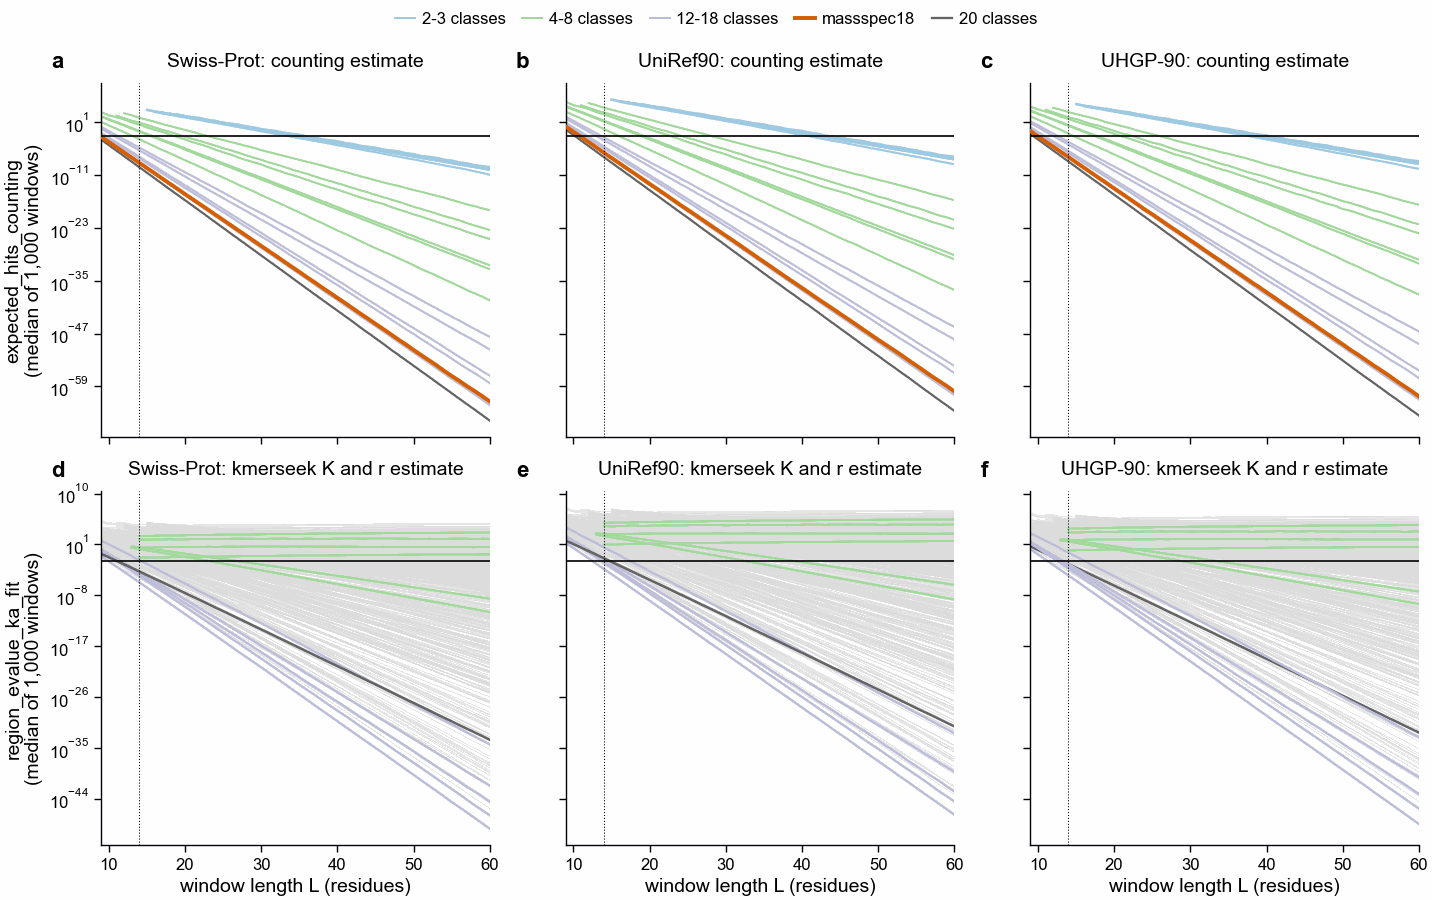

In [5]:
single = est.filter(pl.col("ka_fit_status") != "pair")
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 115, nrows=2, ncols=3, sharex=True, sharey="row")
for j, (db, db_label) in enumerate(DATABASES.items()):
    d = single.filter(pl.col("database") == db)
    ax = axs[0, j]
    for a in ALPHABET_ORDER:
        da = (
            d.filter(pl.col("alphabet") == a)
            .group_by("window_length")
            .agg(pl.col("expected_hits_counting").first())
            .sort("window_length")
        )
        is_hi = a == HIGHLIGHT
        ax.plot(
            da["window_length"],
            da["expected_hits_counting"],
            color=HIGHLIGHT_COLOUR if is_hi else GROUP_TINT[group_of(a)],
            lw=1.4 if is_hi else 0.8,
            zorder=4 if is_hi else 2,
            label=HIGHLIGHT if is_hi else group_of(a),
        )
    ax.set_title(f"{db_label}: counting estimate")
    ax2 = axs[1, j]
    fitted = d.filter(pl.col("ka_fit_status") == "fitted")
    for _, g in fitted.group_by("setting"):
        g = g.sort("window_length")
        ax2.plot(
            g["window_length"],
            g["region_evalue_ka_fit"],
            color="#dddddd",
            lw=0.3,
            zorder=1,
            rasterized=True,
        )
    at14 = fitted.filter(pl.col("window_length") == 14)
    best = at14.sort("region_evalue_ka_fit").group_by("alphabet").first()
    for a, s in best.select("alphabet", "setting").iter_rows():
        g = fitted.filter(pl.col("setting") == s).sort("window_length")
        ax2.plot(
            g["window_length"],
            g["region_evalue_ka_fit"],
            color=GROUP_TINT[group_of(a)],
            lw=0.9,
            zorder=2,
        )
    ax2.set_title(f"{db_label}: kmerseek K and r estimate")
    ax2.set_xlabel("window length L (residues)")
for ax in axs.flat:
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(mpl.ticker.LogLocator(numticks=7))
    ax.axhline(GATE_E, color="black", lw=0.6, zorder=5)
    ax.axvline(14, color="black", lw=0.4, ls=":", zorder=5)
    ax.set_xlim(9, 60)
axs[0, 0].set_ylabel("expected_hits_counting\n(median of 1,000 windows)")
axs[1, 0].set_ylabel("region_evalue_ka_fit\n(median of 1,000 windows)")
pf.shared_legend(fig, ncol=5, frameon=False)
for ax, letter in zip(axs.flat, "abcdef"):
    pf.panel_label(ax, letter)
pf.save(fig, FIGURES / "sf1_evalue_floor_window_length_swissprot_uniref90_uhgp90")

## 5. The smallest window that reaches E < 0.01, per setting and database

`min_length_counting` and `min_length_ka_fit` are the smallest L at which the median
estimate is below 0.01; empty means no L up to 60 reaches it. The table prints the best
setting of each alphabet; the full table is `300_data/step0/floor_min_length.tsv`.

shape: (20, 7)
┌──────────────────────────┬────────────────────┬───────────────────┬─────────────────┬──────────────────┬─────────────────┬───────────────┐
│ alphabet                 ┆ swissprot_counting ┆ uniref90_counting ┆ uhgp90_counting ┆ swissprot_ka_fit ┆ uniref90_ka_fit ┆ uhgp90_ka_fit │
│ ---                      ┆ ---                ┆ ---               ┆ ---             ┆ ---              ┆ ---             ┆ ---           │
│ str                      ┆ i64                ┆ i64               ┆ i64             ┆ i64              ┆ i64             ┆ i64           │
╞══════════════════════════╪════════════════════╪═══════════════════╪═════════════════╪══════════════════╪═════════════════╪═══════════════╡
│ hp_kyte_doolittle2       ┆ 36                 ┆ 44                ┆ 41              ┆ 60               ┆ null            ┆ null          │
│ hp_lehninger2            ┆ 35                 ┆ 42                ┆ 39              ┆ 52               ┆ null            ┆ 60            

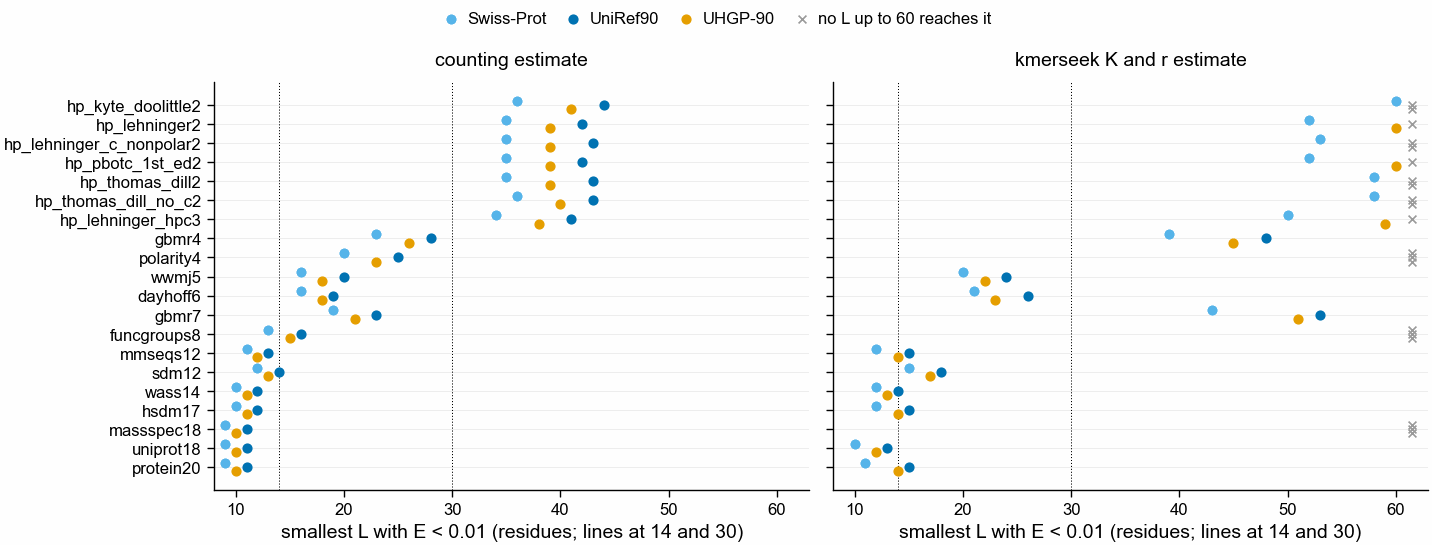

In [6]:
best_min = (
    min_len.sort("min_length_ka_fit", "min_length_counting", nulls_last=True)
    .group_by("alphabet", "database")
    .first()
)
wide = best_min.pivot(on="database", index="alphabet", values="min_length_counting")
wide = wide.select("alphabet", *DATABASES).rename(
    {d: f"{d}_counting" for d in DATABASES}
)
wide_ka = best_min.pivot(on="database", index="alphabet", values="min_length_ka_fit")
wide_ka = wide_ka.select("alphabet", *DATABASES).rename(
    {d: f"{d}_ka_fit" for d in DATABASES}
)
table = (
    wide.join(wide_ka, on="alphabet")
    .with_columns(
        pl.col("alphabet")
        .replace_strict(
            {a: i for i, a in enumerate(ALPHABET_ORDER)}, return_dtype=pl.Int64
        )
        .alias("_o")
    )
    .sort("_o")
    .drop("_o")
)
print(table)

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 70, ncols=2, sharey=True)
y = {a: i for i, a in enumerate(table["alphabet"])}
colours = {
    "swissprot": pf.OKABE_ITO["sky_blue"],
    "uniref90": pf.OKABE_ITO["blue"],
    "uhgp90": pf.OKABE_ITO["orange"],
}
for ax, suffix, title in [
    (axs[0], "counting", "counting estimate"),
    (axs[1], "ka_fit", "kmerseek K and r estimate"),
]:
    for k, db in enumerate(DATABASES):
        col = table[f"{db}_{suffix}"].to_list()
        ys = [
            y[a] + (k - 1) * 0.22
            for a, v in zip(table["alphabet"], col)
            if v is not None
        ]
        ax.scatter(
            [v for v in col if v is not None],
            ys,
            s=10,
            color=colours[db],
            label=DATABASES[db],
            zorder=3,
        )
        miss = [
            y[a] + (k - 1) * 0.22 for a, v in zip(table["alphabet"], col) if v is None
        ]
        ax.scatter(
            [61.5] * len(miss), miss, marker="x", s=8, color=pf.GREY, lw=0.6, zorder=3
        )
    ax.scatter(
        [], [], marker="x", s=8, color=pf.GREY, lw=0.6, label="no L up to 60 reaches it"
    )
    ax.axvline(14, color="black", lw=0.4, ls=":")
    ax.axvline(30, color="black", lw=0.4, ls=":")
    ax.set_xlim(8, 63)
    ax.set_xlabel("smallest L with E < 0.01 (residues; lines at 14 and 30)")
    ax.set_title(title)
    for yy in y.values():
        ax.axhline(yy, color="#eeeeee", lw=0.4, zorder=0)
axs[0].set_yticks(list(y.values()), list(y))
axs[0].invert_yaxis()
pf.shared_legend(fig, ncol=4, frameon=False)
pf.save(fig, FIGURES / "step0_min_window_length_by_alphabet")

## 6. Where the two estimates disagree by more than a factor of 3

`counting_over_ka` is `expected_hits_counting / region_evalue_ka_fit`. Above 3, the kmerseek
formula calls a window more significant than the chance count says; below 1/3, less. Shown at
L = 14 against UHGP-90.

shape: (12, 6)
┌─────────────┬────────────┬────────────┬─────────────────────────┬──────────────────────┬──────────────────────┐
│ alphabet    ┆ n_settings ┆ n_disagree ┆ counting_over_ka_median ┆ counting_over_ka_min ┆ counting_over_ka_max │
│ ---         ┆ ---        ┆ ---        ┆ ---                     ┆ ---                  ┆ ---                  │
│ str         ┆ u32        ┆ u32        ┆ f64                     ┆ f64                  ┆ f64                  │
╞═════════════╪════════════╪════════════╪═════════════════════════╪══════════════════════╪══════════════════════╡
│ protein20   ┆ 60         ┆ 60         ┆ 3.4362e-10              ┆ 2.0445e-11           ┆ 0.000004             │
│ uniprot18   ┆ 63         ┆ 63         ┆ 3.9430e-9               ┆ 3.1042e-10           ┆ 0.002679             │
│ hsdm17      ┆ 65         ┆ 65         ┆ 1.3987e-8               ┆ 2.5549e-9            ┆ 0.000798             │
│ wass14      ┆ 61         ┆ 61         ┆ 1.2215e-7               ┆ 6.471

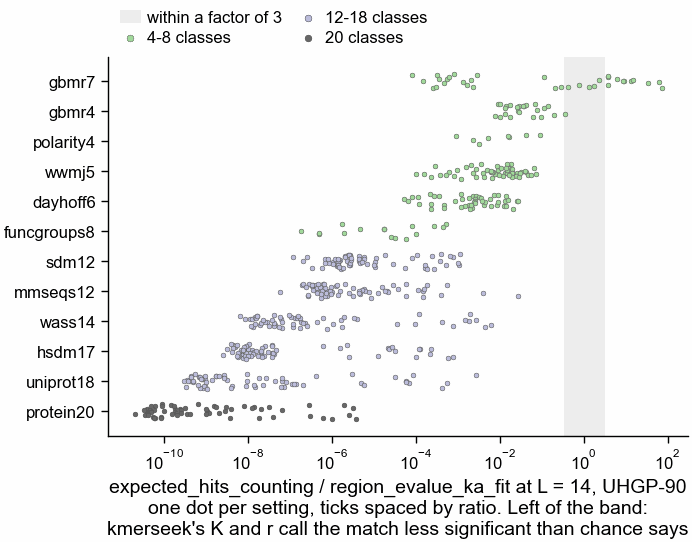

In [7]:
d14 = est.filter(
    (pl.col("window_length") == 14)
    & (pl.col("database") == "uhgp90")
    & pl.col("region_evalue_ka_fit").is_not_null()
)
summary = (
    d14.group_by("alphabet")
    .agg(
        n_settings=pl.len(),
        n_disagree=pl.col("estimates_disagree").sum(),
        counting_over_ka_median=pl.col("counting_over_ka").median(),
        counting_over_ka_min=pl.col("counting_over_ka").min(),
        counting_over_ka_max=pl.col("counting_over_ka").max(),
    )
    .sort("counting_over_ka_median")
)
print(summary)

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 70)
order = summary["alphabet"].to_list()
for i, a in enumerate(order):
    v = d14.filter(pl.col("alphabet") == a)["counting_over_ka"].to_numpy()
    ax.scatter(
        v,
        np.full(len(v), i) + np.random.default_rng(i).uniform(-0.25, 0.25, len(v)),
        s=3,
        color=GROUP_TINT[group_of(a)],
        edgecolors="#555555",
        linewidths=0.2,
    )
ax.axvspan(1 / 3, 3, color="#eeeeee", zorder=0, label="within a factor of 3")
for name, *_ in GROUPS:
    if any(group_of(a) == name for a in order):
        ax.scatter(
            [],
            [],
            s=6,
            color=GROUP_TINT[name],
            edgecolors="#555555",
            linewidths=0.2,
            label=name,
        )
ax.set_xscale("log")
ax.set_yticks(range(len(order)), order)
ax.set_xlabel(
    "expected_hits_counting / region_evalue_ka_fit at L = 14, UHGP-90\n"
    "one dot per setting, ticks spaced by ratio. Left of the band:\n"
    "kmerseek's K and r call the match less significant than chance says"
)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False, ncol=2)
pf.save(fig, FIGURES / "step0_counting_vs_ka_fit_uhgp90")

## 7. Settings with no fit

Listed, not skipped. A setting with no stored fit gets no `region_evalue_ka_fit`; its counting
estimate is still in every table above.

1636 kmerseek settings:
shape: (3, 2)
┌────────────────────────────────────┬──────┐
│ ka_fit_status                      ┆ len  │
│ ---                                ┆ ---  │
│ str                                ┆ u32  │
╞════════════════════════════════════╪══════╡
│ fitted                             ┆ 1473 │
│ no index: alphabet not in kmerseek ┆ 5    │
│ no fit stored                      ┆ 158  │
└────────────────────────────────────┴──────┘
shape: (15, 4)
┌──────────────────────┬────────────────────────────────────┬────────────┬────────────────┐
│ alphabet             ┆ ka_fit_status                      ┆ n_settings ┆ ksizes         │
│ ---                  ┆ ---                                ┆ ---        ┆ ---            │
│ str                  ┆ str                                ┆ u32        ┆ list[i64]      │
╞══════════════════════╪════════════════════════════════════╪════════════╪════════════════╡
│ dayhoff6             ┆ no fit stored                      ┆ 14         

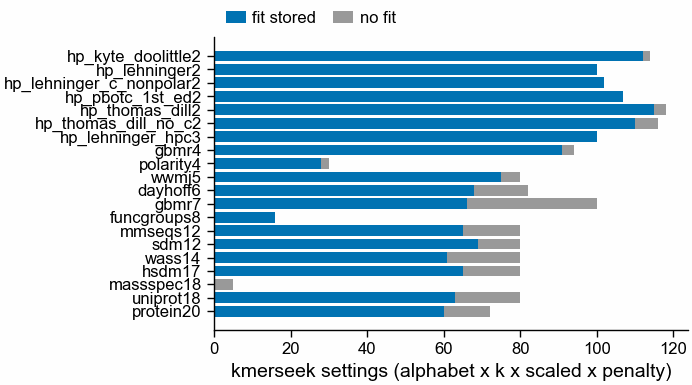

In [8]:
print(f"{len(settings)} kmerseek settings:")
print(settings.group_by("ka_fit_status").len())
nofit = settings.filter(pl.col("ka_fit_status") != "fitted")
print(
    nofit.group_by("alphabet", "ka_fit_status")
    .agg(n_settings=pl.len(), ksizes=pl.col("ksize").unique().sort())
    .sort("alphabet")
)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 50)
counts = settings.group_by("alphabet").agg(
    fitted=(pl.col("ka_fit_status") == "fitted").sum(),
    no_fit=(pl.col("ka_fit_status") != "fitted").sum(),
)
counts = counts.with_columns(
    pl.col("alphabet")
    .replace_strict({a: i for i, a in enumerate(ALPHABET_ORDER)}, return_dtype=pl.Int64)
    .alias("_o")
).sort("_o")
yy = np.arange(len(counts))
ax.barh(yy, counts["fitted"], color=pf.OKABE_ITO["blue"], label="fit stored")
ax.barh(yy, counts["no_fit"], left=counts["fitted"], color=pf.GREY, label="no fit")
ax.set_yticks(yy, counts["alphabet"])
ax.invert_yaxis()
ax.set_xlabel("kmerseek settings (alphabet x k x scaled x penalty)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False, ncol=2)
pf.save(fig, FIGURES / "step0_settings_with_and_without_fit")

## 8. Step 0 verdict (run of 2026-10-20, databases read that day)

**Dead: all 7 HP alphabets.** `hp_lehninger2`, `hp_thomas_dill2`, `hp_kyte_doolittle2`,
`hp_thomas_dill_no_c2`, `hp_lehninger_c_nonpolar2`, `hp_lehninger_hpc3` and `hp_pbotc_1st_ed2`.
The smallest k any of them was indexed at is 15 to 19, longer than a 14-residue window, and two
seeds of 15 need 31 residues, more than the longest peptide. Even ignoring the seed, one exact
window needs 38 to 41 residues to reach `expected_hits_counting` < 0.01 against UHGP-90
(section 5). Peptide lookup is not possible with a two- or three-class alphabet.

**Alive: the other 12**, `massspec18` among them. Against UHGP-90 (4.37 billion residues):

* `protein20`, `uniprot18` and `massspec18` reach `expected_hits_counting` < 0.01 with one exact
  window of 10 residues, and a 14-residue window gives 1.3e-8 to 1.4e-7.
* `wass14`, `hsdm17`, `mmseqs12` and `sdm12` need 11 to 13 residues.
* `funcgroups8`, `dayhoff6`, `wwmj5`, `gbmr7`, `polarity4` and `gbmr4` need 15 to 26 residues for
  one window, so a 14-residue window does not pass; they pass the gate only through a pair of
  windows inside a 30-residue peptide. Most de novo peptides are shorter than 30, so these six are
  alive only for the longest peptides.

**The two estimates do not agree.** At L = 14 against UHGP-90, every fitted setting but 6 gives a
`region_evalue_ka_fit` more than 3 times `expected_hits_counting`, and for `protein20` the
median ratio is 3e9: kmerseek's stored K and r call an exact 14-residue match far less
significant than its chance count says. With K and r alone, only `protein20` (3.3e-3),
`uniprot18`, `hsdm17`, `wass14` and `mmseqs12` reach E < 0.01 at 14 residues. This is the size of
error notebook 344
([PR 174](https://github.com/seanome/2024-kmerseek-analysis/pull/174)) found for region E-values, in the conservative direction here, and it bears on
pass rule 2 (decoy FDR crossing 1% within a factor of 2 of E = 0.01): that rule is likely to fail
on calibration, not on recovery.

**What this decides.** Steps 1-6 run. Kill test 3 is not killed by Step 0. Which k each
alphabet runs at is section 9.

## 9. One k per alphabet: the bits of protein20 at k = 7

Olga, 2026-10-21: "let's use 1 ksize per alphabet, use the equivalent of protein k=7 bits for
each alphabet". So each alphabet runs at the one k whose k-mer carries as much information as
a protein20 7-mer.

Bits per position is the Shannon entropy of the alphabet's class frequencies measured on
UHGP-90, the database searched: H = -sum over classes of f log2 f. Bits per k-mer is k x H.
Protein20 at k = 7 carries 7 x 4.165 = 29.2 bits, so an alphabet runs at k = round(29.2 / H).
The column `ksize_uniform` is the rule kmerseek's own tests use, k x log2(classes), which treats
every class as equally common; it is shown for comparison and not used.

The gate is then read again at that one k. A k above 14 cannot seed in a 14-residue window,
and two seeds need 2k + 1 residues, so a k above 14 is dead for peptides of 30 or fewer.

protein20 at k = 7: 29.2 bits
shape: (20, 9)
┌──────────────────────────┬───────────┬───────────────────┬───────┬───────────────┬───────────────┬──────────────────────────────┬─────────────────────────────┬───────────────────┐
│ alphabet                 ┆ n_classes ┆ bits_per_position ┆ ksize ┆ bits_per_kmer ┆ ksize_uniform ┆ expected_hits_counting_at_14 ┆ expected_hits_counting_pair ┆ verdict_at_this_k │
│ ---                      ┆ ---       ┆ ---               ┆ ---   ┆ ---           ┆ ---           ┆ ---                          ┆ ---                         ┆ ---               │
│ str                      ┆ i64       ┆ f64               ┆ i64   ┆ f64           ┆ i64           ┆ f64                          ┆ f64                         ┆ str               │
╞══════════════════════════╪═══════════╪═══════════════════╪═══════╪═══════════════╪═══════════════╪══════════════════════════════╪═════════════════════════════╪═══════════════════╡
│ hp_kyte_doolittle2       ┆ 2         ┆ 0.96

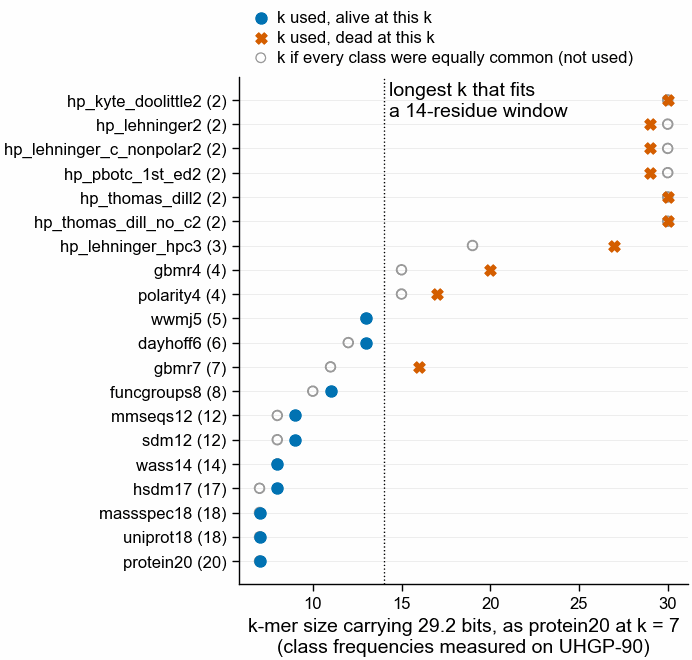

In [9]:
import math

uhgp = json.loads((DATA / "composition_uhgp90.json").read_text())
sys.path.insert(0, str(Path.cwd().parent / "nextflow-runs" / "peptide-lookup" / "bin"))
from evalue_floor import class_frequencies


def entropy_bits(alphabet):
    return -sum(f * math.log2(f) for f in class_frequencies(uhgp, alphabet) if f > 0)


PROTEIN_K = 7
target_bits = PROTEIN_K * entropy_bits("protein20")
pair_rows = est.filter(pl.col("ka_fit_status") == "pair")
rows = []
for a in ALPHABET_ORDER:
    h = entropy_bits(a)
    k = round(target_bits / h)
    single = est.filter(
        (pl.col("alphabet") == a)
        & (pl.col("window_length") == 14)
        & (pl.col("ka_fit_status") != "pair")
    )
    counting_14 = (
        single["expected_hits_counting"].median() if k <= 14 and len(single) else None
    )
    pair_e = None
    if 2 * k + 1 <= 30:
        p = pair_rows.filter(pl.col("alphabet") == a).sort("ksize").row(0, named=True)
        # the pair count scales with the number of places the unmatched residue can sit
        pair_e = p["expected_hits_counting_pair"] * (30 - 2 * k) / (30 - 2 * p["ksize"])
    alive = any(v is not None and v < GATE_E for v in (counting_14, pair_e))
    rows.append(
        {
            "alphabet": a,
            "n_classes": len(CLUSTERS[a]),
            "bits_per_position": round(h, 3),
            "ksize": k,
            "bits_per_kmer": round(k * h, 1),
            "ksize_uniform": round(
                PROTEIN_K * math.log2(20) / math.log2(len(CLUSTERS[a]))
            ),
            "expected_hits_counting_at_14": counting_14,
            "expected_hits_counting_pair": pair_e,
            "verdict_at_this_k": "alive" if alive else "dead",
        }
    )
ksizes = pl.DataFrame(rows)
ksizes.write_csv(DATA.parent / "settings_one_k_per_alphabet.tsv", separator="\t")
print(f"protein20 at k = {PROTEIN_K}: {target_bits:.1f} bits")
print(ksizes)

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 85)
y = np.arange(len(ksizes))
for yi, r in zip(y, ksizes.iter_rows(named=True)):
    alive = r["verdict_at_this_k"] == "alive"
    ax.scatter(
        r["ksize"],
        yi,
        s=16,
        marker="o" if alive else "X",
        color=pf.OKABE_ITO["blue"] if alive else HIGHLIGHT_COLOUR,
        zorder=3,
    )
    ax.scatter(
        r["ksize_uniform"],
        yi,
        s=12,
        facecolors="none",
        edgecolors=pf.GREY,
        linewidths=0.7,
        zorder=2,
    )
ax.scatter(
    [],
    [],
    s=16,
    marker="o",
    color=pf.OKABE_ITO["blue"],
    label="k used, alive at this k",
)
ax.scatter(
    [], [], s=16, marker="X", color=HIGHLIGHT_COLOUR, label="k used, dead at this k"
)
ax.scatter(
    [],
    [],
    s=12,
    facecolors="none",
    edgecolors=pf.GREY,
    label="k if every class were equally common (not used)",
)
ax.axvline(14, color="black", lw=0.5, ls=":")
ax.text(
    14.3,
    0.99,
    "longest k that fits\na 14-residue window",
    va="top",
    transform=ax.get_xaxis_transform(),
)
ax.set_yticks(
    y, [f"{a} ({n})" for a, n in ksizes.select("alphabet", "n_classes").iter_rows()]
)
for yy in y:
    ax.axhline(yy, color="#eeeeee", lw=0.4, zorder=0)
ax.invert_yaxis()
ax.set_xlabel(
    f"k-mer size carrying {target_bits:.1f} bits, as protein20 at k = 7\n"
    "(class frequencies measured on UHGP-90)"
)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False)
pf.save(fig, FIGURES / "one_ksize_per_alphabet_protein20_k7_bits_uhgp90")

At one k per alphabet, `gbmr7` (k 16), `polarity4` (k 17) and `gbmr4` (k 20) join the HP
alphabets as dead: none can seed in 14 residues, and two seeds do not fit in 30. The table
above lists the alphabets that stay alive and the k each runs at in steps 1-6.

## 10. Steps 1-3: the query peptides, their decoys and the search database

**No public de novo list.** The task asked for a human gut metaproteomics dataset on PRIDE that
ships a de novo peptide list (PEAKS, Novor or Casanovo) with a confidence score.
`bin/pride_denovo_search.py` (run 2026-10-21) found 477 gut microbiome projects. Eight have
a file whose name suggests de novo output, and none is a human gut de novo peptide list with a
score. The table below says what each is.

**So this is the fallback, and a weaker test.** The real peptides are database-search hits
from PXD069517 (stool of celiac disease patients; Sequest-HT and Percolator against a
collection of human gut metagenomes, "MGDB"; Confidence "High"). Every UHGP-90 protein that
contains one of them exactly, with I and L read as the same letter, is hidden from the
database kmerseek searches. It is weaker than the planned test in three ways:

1. A database-search peptide has no sequencing errors: the search engine reports the residues
   of the protein it matched. A de novo peptide carries swaps (I/L, Q/K, N/D) and can have two
   residues in the wrong order. Only the spiked peptides test swaps here.
2. Every real peptide matched a protein in the study's database, so a close relative of its
   source very likely remains in UHGP-90 after the exact matches are hidden. Peptides no
   database explains, which is what de novo lists are used for, would be harder.
3. All are tryptic peptides that passed a 1% FDR search, so they are short and clean.

Pass rule 1 compares kmerseek with `diamond` on these real peptides. That comparison stays
fair, because both tools search the same database with the same proteins hidden.

**Spiked peptides.** 1,000 windows of UHGP-90 proteins (`bin/spike_peptides.py`, seed 300).
Their lengths are drawn from the real peptides' lengths, so the two sets are equally short. Each
has one or two conservative swaps (I<->L, D<->E, K<->R) at recorded positions, and its source
protein stays in the database.

**Decoys.** One per peptide: the first and last residue kept, the rest reversed
(`bin/make_queries.py`). Same length, mass and residue counts.

**Database.** UHGP-90 minus the hidden proteins, the human reference proteome UP000005640 with
its isoforms, and cRAP.

shape: (8, 3)
┌───────────┬───────────────────────────────────────┬────────────────────────┐
│ accession ┆ organism                              ┆ usable_as_de_novo_list │
│ ---       ┆ ---                                   ┆ ---                    │
│ str       ┆ str                                   ┆ str                    │
╞═══════════╪═══════════════════════════════════════╪════════════════════════╡
│ PXD030708 ┆ human gut (mucosal-luminal interface) ┆ no                     │
│ PXD043896 ┆ honeybee gut                          ┆ no                     │
│ PXD051792 ┆ mouse faeces                          ┆ no                     │
│ PXD060439 ┆ sheep faeces                          ┆ no                     │
│ PXD070030 ┆ mouse (Prevotella arthritis model)    ┆ no                     │
│ PXD073688 ┆ mouse colon                           ┆ no                     │
│ PXD077115 ┆ chicken caecum                        ┆ no                     │
│ PXD077163 ┆ chicken caecum          

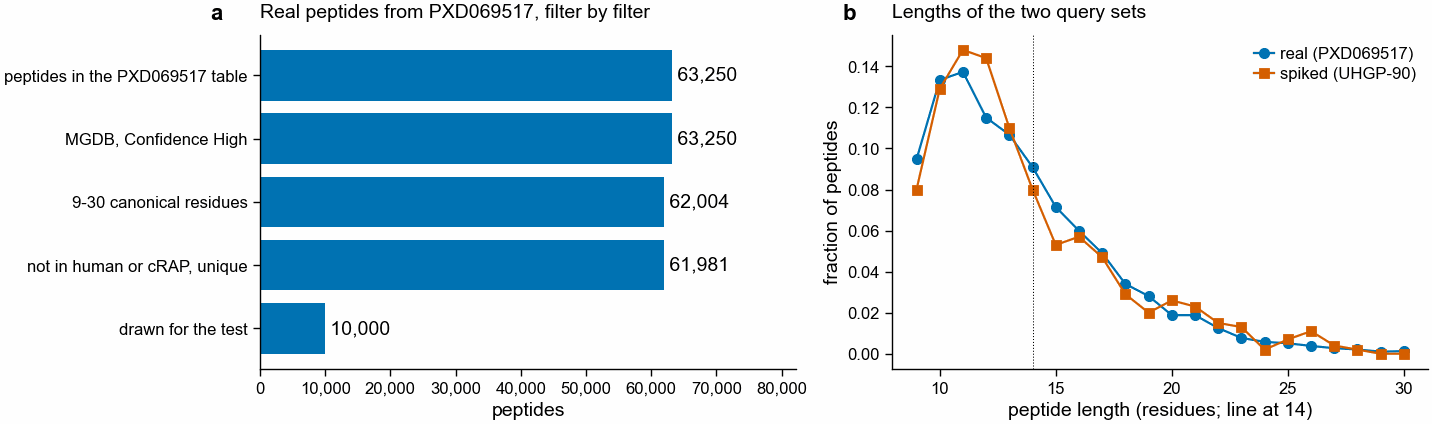

In [10]:
S1 = DATA.parent / "step1"
print(
    pl.read_csv(S1 / "pride_denovo_files_checked.tsv", separator="\t").select(
        "accession", "organism", "usable_as_de_novo_list"
    )
)
filt = pl.read_csv(S1 / "real_peptide_filter_counts.tsv", separator="\t")
real = pl.read_csv(S1 / "real_peptides.tsv", separator="\t")
spiked = pl.read_csv(S1 / "spiked_peptides.tsv", separator="\t")
queries = pl.read_csv(S1 / "queries.tsv", separator="\t")
dbc = pl.read_csv(S1 / "search_db_counts.tsv", separator="\t")
hidden = (S1 / "uhgp90_hidden_proteins.txt").read_text().split()

steps = [
    ("peptides in the PXD069517 table", filt["rows_in_file"][0]),
    ("MGDB, Confidence High", filt["mgdb_high_confidence"][0]),
    ("9-30 canonical residues", filt["length_9_30_canonical"][0]),
    ("not in human or cRAP, unique", filt["unique_pool"][0]),
    ("drawn for the test", len(real)),
]
funnel = pl.DataFrame(steps, schema=["step", "n_peptides"], orient="row")
print(funnel)
n_exact = int((real["n_uhgp90_proteins_with_exact_match"] > 0).sum())
print(
    f"{n_exact} of {len(real)} real peptides occur exactly (I = L) in UHGP-90; "
    f"{len(hidden):_} UHGP-90 proteins hidden"
)
print(dbc)

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 55, ncols=2)
ax = axs[0]
yy = np.arange(len(funnel))
ax.barh(yy, funnel["n_peptides"], color=pf.OKABE_ITO["blue"])
for y_, n in zip(yy, funnel["n_peptides"]):
    ax.text(n, y_, f" {n:,}", va="center")
ax.set_yticks(yy, funnel["step"])
ax.invert_yaxis()
ax.set_xlim(0, funnel["n_peptides"].max() * 1.3)
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("peptides")
ax.set_title("Real peptides from PXD069517, filter by filter", loc="left")
ax = axs[1]
lengths = np.arange(9, 31)
for name, table, colour, marker in [
    ("real (PXD069517)", real, pf.OKABE_ITO["blue"], "o"),
    ("spiked (UHGP-90)", spiked, HIGHLIGHT_COLOUR, "s"),
]:
    counts = table["length"].value_counts()
    frac = [
        counts.filter(pl.col("length") == L)["count"].sum() / len(table)
        for L in lengths
    ]
    ax.plot(lengths, frac, marker=marker, ms=3, lw=0.8, color=colour, label=name)
ax.axvline(14, color="black", lw=0.4, ls=":")
ax.set_xlabel("peptide length (residues; line at 14)")
ax.set_ylabel("fraction of peptides")
ax.legend(frameon=False)
ax.set_title("Lengths of the two query sets", loc="left")
for a_, letter in zip(axs, "ab"):
    pf.panel_label(a_, letter)
pf.save(fig, FIGURES / "step1_real_peptide_filters_and_lengths_pxd069517_uhgp90")

shape: (2, 2)
┌─────────┬─────┐
│ n_swaps ┆ len │
│ ---     ┆ --- │
│ i64     ┆ u32 │
╞═════════╪═════╡
│ 1       ┆ 500 │
│ 2       ┆ 500 │
└─────────┴─────┘
shape: (3, 2)
┌───────┬─────┐
│ pair  ┆ len │
│ ---   ┆ --- │
│ str   ┆ u32 │
╞═══════╪═════╡
│ D<->E ┆ 481 │
│ I<->L ┆ 628 │
│ K<->R ┆ 391 │
└───────┴─────┘
shape: (4, 4)
┌────────┬──────────┬───────┬─────────────────────┐
│ set    ┆ is_decoy ┆ n     ┆ decoy_equals_target │
│ ---    ┆ ---      ┆ ---   ┆ ---                 │
│ str    ┆ bool     ┆ u32   ┆ u32                 │
╞════════╪══════════╪═══════╪═════════════════════╡
│ real   ┆ false    ┆ 10000 ┆ 0                   │
│ real   ┆ true     ┆ 10000 ┆ 0                   │
│ spiked ┆ false    ┆ 1000  ┆ 0                   │
│ spiked ┆ true     ┆ 1000  ┆ 0                   │
└────────┴──────────┴───────┴─────────────────────┘


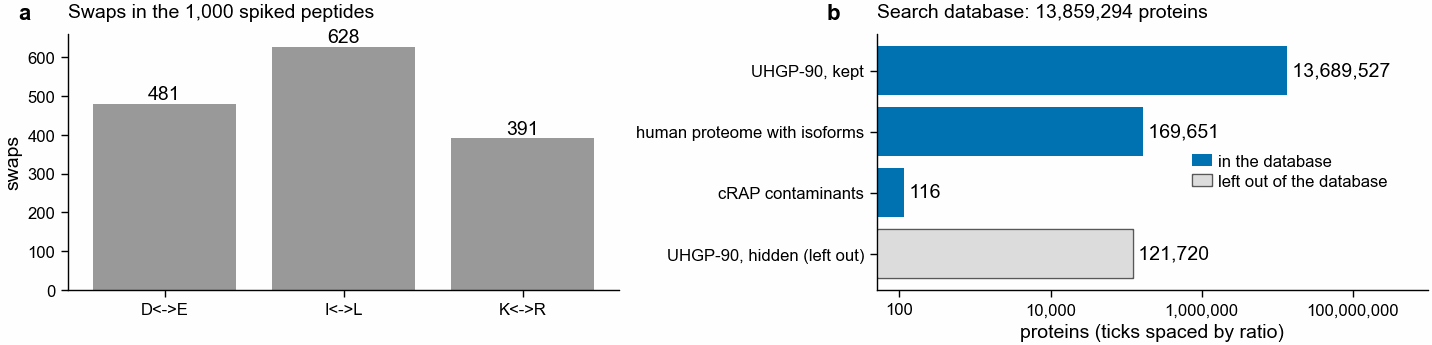

In [11]:
swaps = (
    spiked.select("peptide_id", "n_swaps", pl.col("swaps").str.split(","))
    .explode("swaps")
    .with_columns(
        pair=pl.col("swaps").str.extract(r":(\w)>(\w)", 1)
        + "<->"
        + pl.col("swaps").str.extract(r":(\w)>(\w)", 2)
    )
)
swaps = swaps.with_columns(
    pair=pl.col("pair").replace({"L<->I": "I<->L", "E<->D": "D<->E", "R<->K": "K<->R"})
)
print(spiked.group_by("n_swaps").len().sort("n_swaps"))
print(swaps.group_by("pair").len().sort("pair"))
print(
    queries.group_by("set", "is_decoy")
    .agg(n=pl.len(), decoy_equals_target=pl.col("decoy_equals_target").sum())
    .sort("set", "is_decoy")
)

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 45, ncols=2)
pairs = swaps.group_by("pair").len().sort("pair")
axs[0].bar(pairs["pair"], pairs["len"], color=pf.GREY)
for x_, n in enumerate(pairs["len"]):
    axs[0].text(x_, n, f"{n}", ha="center", va="bottom")
axs[0].set_ylabel("swaps")
axs[0].set_title("Swaps in the 1,000 spiked peptides", loc="left")
labels = {
    "uhgp90_kept": "UHGP-90, kept",
    "human_with_isoforms": "human proteome with isoforms",
    "crap": "cRAP contaminants",
    "uhgp90_hidden": "UHGP-90, hidden (left out)",
}
parts = (
    dbc.filter(pl.col("part") != "total")
    .with_columns(
        order=pl.col("part").replace_strict(
            {k: i for i, k in enumerate(labels)}, return_dtype=pl.Int64
        )
    )
    .sort("order")
)
for y_, (part, n) in enumerate(parts.select("part", "n_sequences").iter_rows()):
    hidden_part = part == "uhgp90_hidden"
    axs[1].barh(
        y_,
        n,
        color="#dddddd" if hidden_part else pf.OKABE_ITO["blue"],
        edgecolor="#555555" if hidden_part else "none",
        lw=0.5,
        label=(
            ("left out of the database" if hidden_part else "in the database")
            if part in ("uhgp90_hidden", "uhgp90_kept")
            else None
        ),
    )
    axs[1].text(n, y_, f" {n:,}", va="center")
axs[1].set_yticks(range(len(parts)), [labels[p] for p in parts["part"]])
axs[1].invert_yaxis()
axs[1].set_xscale("log")
axs[1].set_xlim(50, 1e9)
axs[1].xaxis.set_major_locator(mpl.ticker.FixedLocator([1e2, 1e4, 1e6, 1e8]))
axs[1].xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axs[1].xaxis.set_minor_locator(mpl.ticker.NullLocator())
axs[1].set_xlabel("proteins (ticks spaced by ratio)")
axs[1].legend(frameon=False, loc="lower left", bbox_to_anchor=(0.55, 0.35))
total = dbc.filter(pl.col("part") == "total")["n_sequences"][0]
axs[1].set_title(f"Search database: {total:,} proteins", loc="left")
for a_, letter in zip(axs, "ab"):
    pf.panel_label(a_, letter)
pf.save(fig, FIGURES / "step1_spiked_swaps_and_search_database_uhgp90")

Five peptides of each kind, with their source. For a spiked peptide the source window and the
peptide are aligned residue by residue; `|` marks a residue that is the same, a space a swap.

In [12]:
for r in spiked.head(5).iter_rows(named=True):
    match = "".join(
        "|" if a == b else " " for a, b in zip(r["source_window"], r["peptide"])
    )
    n_same = match.count("|")
    print(
        f"{r['peptide_id']}  {r['source_protein']} {r['source_start_1based']}-"
        f"{r['source_end_1based']}  swaps {r['swaps']}  {n_same} of {r['length']} identical"
    )
    print(
        f"  source   {r['source_window']}\n           {match}\n  peptide  {r['peptide']}"
    )
print()
print(
    real.head(5).select(
        "peptide_id",
        "Sequence",
        "Master Protein Accessions",
        "genus",
        "n_uhgp90_proteins_with_exact_match",
    )
)

spike0001  MGYG000228612_01869 532-540  swaps 1:I>L  8 of 9 identical
  source   ITAIFGAKA
            ||||||||
  peptide  LTAIFGAKA
spike0002  MGYG000126379_01523 208-216  swaps 1:D>E,8:D>E  7 of 9 identical
  source   DAFDGDADI
            |||||| |
  peptide  EAFDGDAEI
spike0003  MGYG000094847_00286 375-384  swaps 1:D>E  9 of 10 identical
  source   DGVQQLAYSL
            |||||||||
  peptide  EGVQQLAYSL
spike0004  MGYG000276714_01980 170-183  swaps 3:D>E,5:I>L  12 of 14 identical
  source   LCDWIEQTPVVCAW
           || | |||||||||
  peptide  LCEWLEQTPVVCAW
spike0005  MGYG000003687_01749 603-611  swaps 6:L>I  8 of 9 identical
  source   INFNTLHAT
           ||||| |||
  peptide  INFNTIHAT

shape: (5, 5)
┌────────────┬───────────────┬─────────────────────────────────────────────────────────────────────────┬───────────────────────┬────────────────────────────────────┐
│ peptide_id ┆ Sequence      ┆ Master Protein Accessions                                               ┆ genus           